# EDA – Thống kê mô tả dữ liệu (Đề tài 1, miền Giáo dục)

Dữ liệu: **VIVOS** (ASR), **FLEURS vi_vn + en_us** (ASR + câu Anh song song), **PhoMT** (song ngữ), nhãn miền **FLoRes+**.
Pipeline dữ liệu `scripts/data/viec1`–`viec4`, chạy trên dữ liệu tải mới 29–30/10/2026 (tái lập đúng hash).
Notebook chỉ **đọc bảng kết quả** trong `reports/data/` và `reports/domain/` rồi vẽ – không tải hay xử lý lại dữ liệu.
Văn bản PhoMT không được phân phối lại (giấy phép) nên chỉ có số đếm.

In [1]:
import json, csv, re
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, Markdown, display

# Tìm thư mục gốc chứa reports/ (task3/ hoặc experiments/ của repo sản phẩm)
ung_vien = [Path.cwd().parent / "experiments", Path.cwd().parent, Path.cwd(), Path(r"D:\CAIDCM\teamwork\task3")]
BASE = next(c for c in ung_vien if (c / "reports" / "data" / "eda").exists())
R = BASE / "reports"
print("Đọc kết quả từ:", BASE)
pd.set_option("display.max_colwidth", 120); pd.set_option("display.width", 200)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": .3, "axes.spines.top": False, "axes.spines.right": False})
XANH, CAM, XAM, LUC = "#0E7C86", "#B36B00", "#8A939C", "#2E7D32"
doc = lambda p: pd.read_csv(p, encoding="utf-8-sig")
J = lambda p: json.loads(Path(p).read_text(encoding="utf-8"))

Đọc kết quả từ: D:\CAIDCM\teamwork\task3


## 1. Nguồn dữ liệu

In [2]:
display(doc(R / "data/nguon_du_lieu.csv"))

,Nguồn,Loại,URL / Cách thu thập,Số lượng mẫu,Định dạng file,Dung lượng (MB),Các trường dữ liệu,Giấy phép
0,VIVOS,Online (public),https://huggingface.co/datasets/AILAB-VNUHCM/vivos (gốc: zenodo.org/record/7068130),train 11.660 câu / 46 người nói; test 760 câu / 19 người nói; 14.921 + 0.746 giờ,WAV trong vivos.tar.gz + prompts .txt.gz (16000 Hz),1406.5,"speaker_id, path, audio (wav), sentence; giới tính theo người nói (genders.txt)",['cc-by-nc-sa-4.0']
1,FLEURS vi_vn,Online (public),https://huggingface.co/datasets/google/fleurs (thư mục data/vi_vn),"train 2.994 bản thu / 1.482 câu, 9.076 giờ; dev 361 bản thu / 149 câu, 1.194 giờ; test 857 bản thu / 347 câu, 3.004 giờ",WAV trong audio/{split}.tar.gz + TSV (16000 Hz),2259.1,"id (ID câu FLoRes), file_name, raw_transcription, transcription, phonemes (trống), num_samples, gender",['cc-by-4.0']
2,FLEURS en_us (chỉ lấy câu Anh),Online (public),https://huggingface.co/datasets/google/fleurs (data/en_us/*.tsv),train 1.476 câu; dev 150 câu; test 350 câu,TSV (không dùng audio tiếng Anh),1.9,"id (ghép với vi_vn), raw_transcription = câu Anh tham chiếu",['cc-by-4.0']
3,PhoMT,Online (gated),https://huggingface.co/datasets/vinai/PhoMT,train 2.977.999 cặp; dev 18.719 cặp; test 19.151 cặp,Văn bản song song .vi/.en trong PhoMT.zip,339.4,"câu tiếng Việt (.vi), câu tiếng Anh (.en), song song theo số dòng","Chỉ nghiên cứu/giáo dục, cấm phân phối lại"
4,Dữ liệu tự thu,Offline,Không thu thập,0,-,-,"Nhóm không tự thu âm/khảo sát. Dùng dataset công khai đã có nhãn chuẩn, giữ split gốc để so được với paper; tự thu c...",-


## 2. Làm sạch – số mẫu sau từng bước

,dataset,split,buoc,ten_buoc,truoc,bi_loai,sau
0,fleurs,train,B0_ghep_chong_leakage,Ghép vi-en + chống leakage (viec2_ghep),2994,0,2994
1,fleurs,train,B1_thieu,Thiếu audio / nhãn,2994,67,2927
2,fleurs,train,B2_trung,Trùng lặp,2927,0,2927
3,fleurs,train,B3_hong_nhieu,Audio hỏng / nhiễu,2927,1,2926
4,fleurs,train,B4_16khz,Đổi về 16 kHz mono,2926,0,2926
5,fleurs,train,B5_chuan_hoa_chu,Chuẩn hoá chữ,2926,0,2926
6,fleurs,train,KET_QUA,Sạch (giữ lại),2926,0,2926
7,fleurs,dev,B0_ghep_chong_leakage,Ghép vi-en + chống leakage (viec2_ghep),361,0,361
8,fleurs,dev,B1_thieu,Thiếu audio / nhãn,361,0,361
9,fleurs,dev,B2_trung,Trùng lặp,361,0,361


Tổng bị loại: 72 mẫu


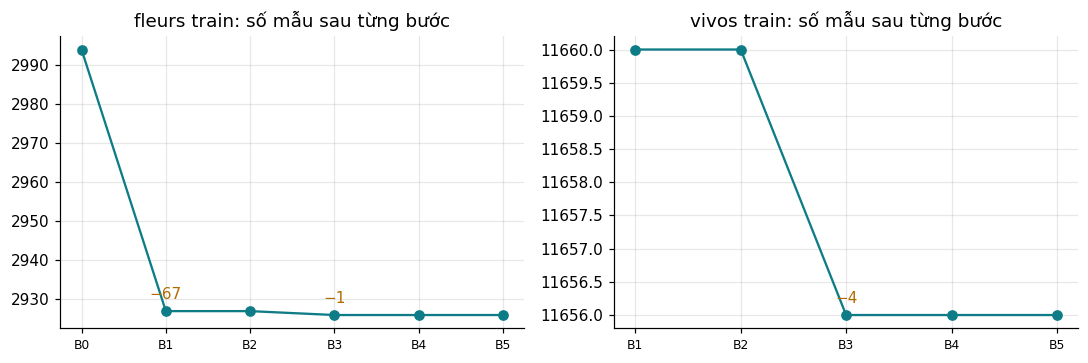

In [3]:
ls = doc(R / "data/lam_sach_dem_tung_buoc.csv")
display(ls[["dataset", "split", "buoc", "ten_buoc", "truoc", "bi_loai", "sau"]])
kq = ls[ls.buoc == "KET_QUA"].assign(tap=lambda d: d.dataset + " " + d.split)
print("Tổng bị loại:", int(ls[ls.buoc != "KET_QUA"].bi_loai.sum()), "mẫu")
buoc = ls[ls.buoc != "KET_QUA"].assign(tap=lambda d: d.dataset + " " + d.split)
tap_co_loai = buoc.groupby("tap").bi_loai.sum().loc[lambda x: x > 0].index
fig, ax = plt.subplots(1, len(tap_co_loai), figsize=(5 * len(tap_co_loai), 3.4), squeeze=False)
for a_, t in zip(ax[0], tap_co_loai):
    d = buoc[buoc.tap == t]; a_.plot(range(len(d)), d.sau, "o-", color=XANH)
    for k, (x, y, l) in enumerate(zip(range(len(d)), d.sau, d.bi_loai)):
        if l: a_.annotate(f"−{l}", (x, y), textcoords="offset points", xytext=(0, 8), ha="center", color=CAM)
    a_.set_xticks(range(len(d))); a_.set_xticklabels(d.buoc.str.split("_").str[0], fontsize=8); a_.set_title(f"{t}: số mẫu sau từng bước")
plt.tight_layout(); plt.show()

## 3. Tỉ lệ train / dev / test

,dataset,split,so_mau,pct_mau,gio,pct_gio,so_cau_goc,so_nguoi_noi
0,fleurs,train,2926,70.61,8.856,67.84,1449,NaN
1,fleurs,dev,361,8.71,1.194,9.15,149,NaN
2,fleurs,test,857,20.68,3.004,23.01,347,NaN
3,vivos,train,11656,93.88,14.918,95.24,11656,46.0
4,vivos,test,760,6.12,0.746,4.76,760,19.0
5,phomt,train,2977170,98.74,NaN,NaN,2977170,NaN
6,phomt,dev,18719,0.62,NaN,NaN,18719,NaN
7,phomt,test,19151,0.64,NaN,NaN,19151,NaN


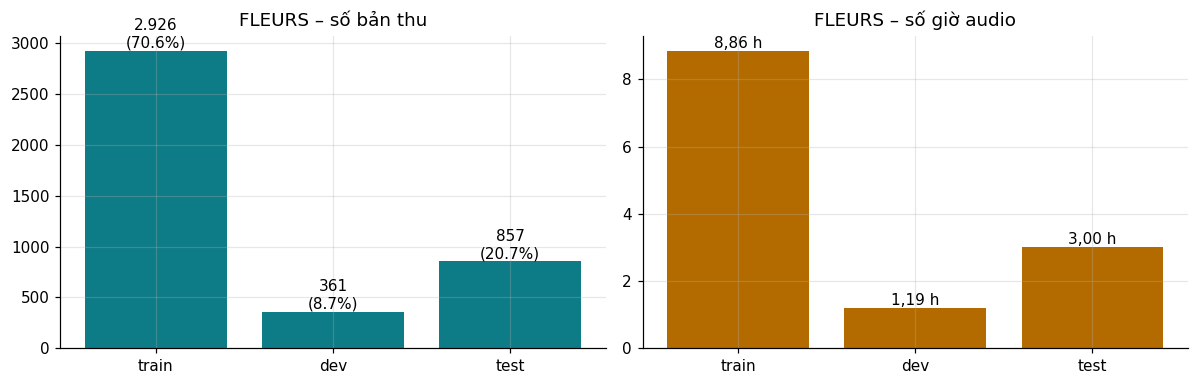

Giữ split gốc của FLEURS (≈ 70,6 / 8,7 / 20,7) để so được với paper và tránh rò rỉ; không ép về 80/10/10.


In [4]:
tl = doc(R / "data/eda/eda_bang_ti_le_tap.csv"); display(tl)
fl = tl[tl.dataset == "fleurs"]
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
ax[0].bar(fl.split, fl.so_mau, color=XANH); ax[0].set_title("FLEURS – số bản thu")
for x, y, p in zip(fl.split, fl.so_mau, fl.pct_mau): ax[0].text(x, y, f"{y:,}\n({p:.1f}%)".replace(",", "."), ha="center", va="bottom")
ax[1].bar(fl.split, fl.gio, color=CAM); ax[1].set_title("FLEURS – số giờ audio")
for x, y in zip(fl.split, fl.gio): ax[1].text(x, y, f"{y:.2f} h".replace(".", ","), ha="center", va="bottom")
plt.tight_layout(); plt.show()
print("Giữ split gốc của FLEURS (≈ 70,6 / 8,7 / 20,7) để so được với paper và tránh rò rỉ; không ép về 80/10/10.")

## 4. Giới tính người nói

,dataset,split,don_vi,Nam,Nữ,Không rõ,pct_Nam,pct_Nữ,pct_Không rõ
0,fleurs,train,mẫu,752,2174,0,25.70,74.30,0.0
1,fleurs,dev,mẫu,361,0,0,100.00,0.00,0.0
2,fleurs,test,mẫu,857,0,0,100.00,0.00,0.0
3,vivos,train,mẫu,4999,6657,0,42.89,57.11,0.0
4,vivos,train,người nói,22,24,0,47.83,52.17,0.0
5,vivos,test,mẫu,480,280,0,63.16,36.84,0.0
6,vivos,test,người nói,12,7,0,63.16,36.84,0.0


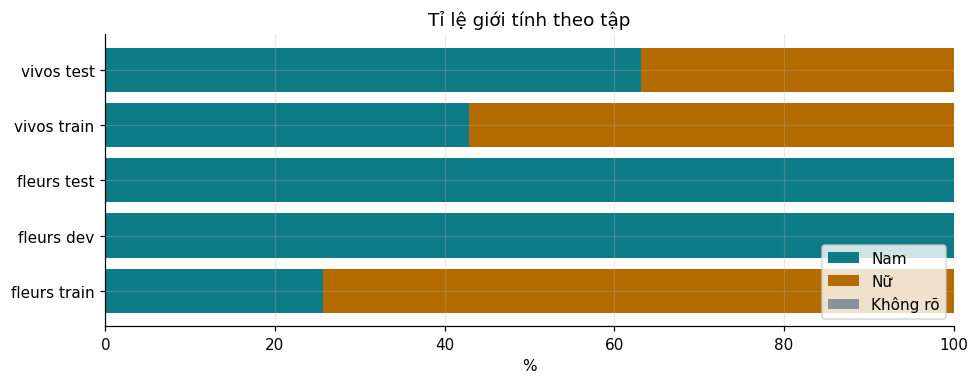

Lệch lớn nhất: FLEURS train phần lớn giọng nữ nhưng dev/test toàn giọng nam → kết quả test chưa nói được gì về giọng nữ.


In [5]:
gt = doc(R / "data/eda/eda_bang_gioi_tinh.csv"); display(gt)
g = gt.assign(tap=gt.dataset + " " + gt.split)
fig, ax = plt.subplots(figsize=(9, 3.6))
ax.barh(g.tap, g.pct_Nam, color=XANH, label="Nam"); ax.barh(g.tap, g["pct_Nữ"], left=g.pct_Nam, color=CAM, label="Nữ")
ax.barh(g.tap, g["pct_Không rõ"], left=g.pct_Nam + g["pct_Nữ"], color=XAM, label="Không rõ")
ax.set_xlabel("%"); ax.legend(loc="lower right"); ax.set_title("Tỉ lệ giới tính theo tập"); plt.tight_layout(); plt.show()
print("Lệch lớn nhất: FLEURS train phần lớn giọng nữ nhưng dev/test toàn giọng nam → kết quả test chưa nói được gì về giọng nữ.")

## 5. Số bản thu mỗi câu (FLEURS) – nguồn mất cân bằng chính

split,dev,test,train
so_ban_thu,,,
1,8.72,9.80,19.74
2,40.27,33.43,58.59
3,51.01,56.77,21.67


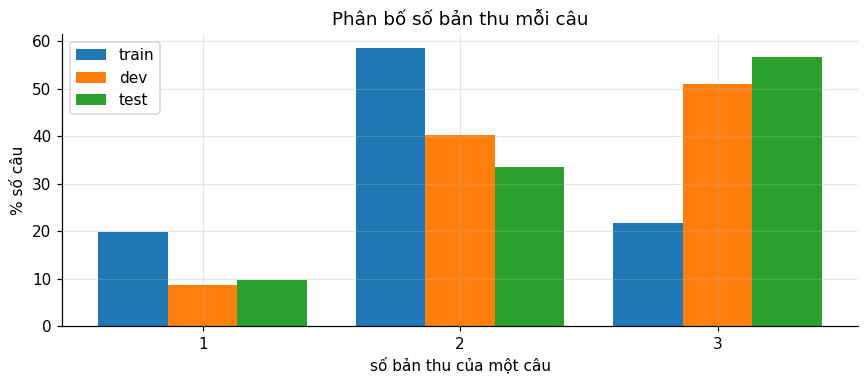

In [6]:
bt = doc(R / "data/eda/eda_bang_ban_thu_moi_cau.csv"); display(bt.pivot(index="so_ban_thu", columns="split", values="pct"))
fig, ax = plt.subplots(figsize=(8, 3.6)); w = .27
for i, sp in enumerate(["train", "dev", "test"]):
    d = bt[bt.split == sp]; ax.bar(d.so_ban_thu + (i - 1) * w, d.pct, w, label=sp)
ax.set_xlabel("số bản thu của một câu"); ax.set_ylabel("% số câu"); ax.set_xticks(sorted(bt.so_ban_thu.unique())); ax.legend()
ax.set_title("Phân bố số bản thu mỗi câu"); plt.tight_layout(); plt.show()

## 6. Thời lượng audio và độ dài câu

,bo_tap,n,mean,median,min,p5,p95,max,pct_tren_30s,so_tren_30s
0,fleurs_train,2926,10.90,10.38,2.52,5.88,17.62,42.18,0.14,4
1,fleurs_dev,361,11.91,11.16,4.32,6.00,21.32,31.98,0.55,2
2,fleurs_test,857,12.62,11.64,4.98,6.96,21.38,38.10,0.82,7
3,vivos_train,11656,4.61,3.88,0.81,2.06,9.34,17.12,0.00,0
4,vivos_test,760,3.53,3.47,1.38,2.00,5.25,7.84,0.00,0


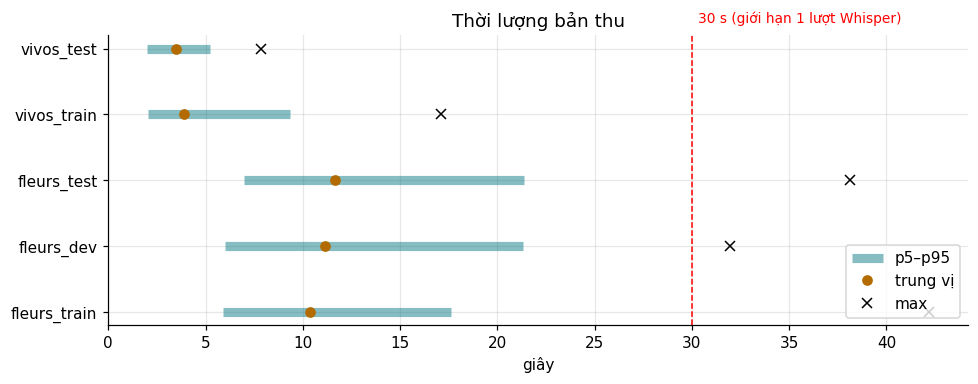

,bo_tap_ngon_ngu,n,mean,median,min,p5,p95,max
0,fleurs_train_vi,2926,28.94,28.0,7,15.0,47.0,75
1,fleurs_train_en,2926,20.73,20.0,6,11.0,33.0,60
2,fleurs_dev_vi,361,28.87,29.0,9,14.0,50.0,66
3,fleurs_dev_en,361,20.20,19.0,8,10.0,32.0,46
4,fleurs_test_vi,857,30.36,28.0,12,15.0,52.0,74
5,fleurs_test_en,857,21.78,21.0,7,11.0,35.0,52
6,vivos_train_vi,11656,13.23,12.0,2,5.0,27.0,30
7,vivos_test_vi,760,10.16,11.0,2,5.0,15.0,18
8,phomt_train_vi,2977170,16.92,12.0,1,5.0,43.0,1827
9,phomt_train_en,2977170,13.26,10.0,1,4.0,33.0,1346


FLEURS test có 7 bản > 30 s – nhóm này PhoWhisper giải mã sai khi đưa thẳng vào model (xem phan_tich_loi.ipynb).


In [7]:
th = doc(R / "data/eda/eda_bang_thoi_luong.csv"); display(th)
fig, ax = plt.subplots(figsize=(9, 3.6))
y = range(len(th)); ax.hlines(y, th.p5, th.p95, color=XANH, lw=6, alpha=.5, label="p5–p95")
ax.plot(th["median"], y, "o", color=CAM, label="trung vị"); ax.plot(th["max"], y, "x", color="k", label="max")
ax.axvline(30, color="red", ls="--", lw=1); ax.text(30.3, len(th) - .6, "30 s (giới hạn 1 lượt Whisper)", color="red", fontsize=9)
ax.set_yticks(list(y)); ax.set_yticklabels(th.bo_tap); ax.set_xlabel("giây"); ax.legend(loc="lower right"); ax.set_title("Thời lượng bản thu")
plt.tight_layout(); plt.show()
dd = doc(R / "data/eda/eda_bang_do_dai_cau.csv"); display(dd)
print("FLEURS test có", int(th[th.bo_tap == "fleurs_test"].so_tren_30s.iloc[0]), "bản > 30 s – nhóm này PhoWhisper giải mã sai khi đưa thẳng vào model (xem phan_tich_loi.ipynb).")

## 7. VIVOS – số câu mỗi người nói

,count,mean,std,min,25%,50%,75%,max
split,,,,,,,,
test,19.0,40.000000,0.00000,40.0,40.0,40.0,40.0,40.0
train,46.0,253.391304,54.94825,100.0,245.5,250.0,300.0,300.0


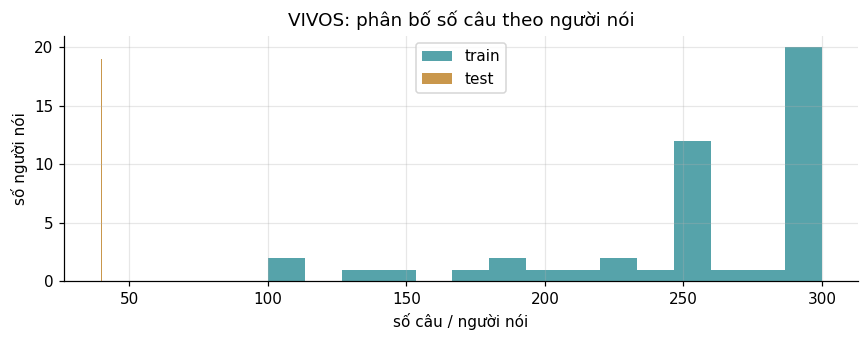

In [8]:
vn_ = doc(R / "data/eda/eda_bang_nguoi_noi_vivos.csv")
display(vn_.groupby("split").so_cau.describe())
fig, ax = plt.subplots(figsize=(8, 3.2))
for sp, c in (("train", XANH), ("test", CAM)):
    ax.hist(vn_[vn_.split == sp].so_cau, bins=15, alpha=.7, color=c, label=sp)
ax.set_xlabel("số câu / người nói"); ax.set_ylabel("số người nói"); ax.legend(); ax.set_title("VIVOS: phân bố số câu theo người nói"); plt.tight_layout(); plt.show()

## 8. Miền văn bản – PhoMT và FLEURS (FLoRes+)

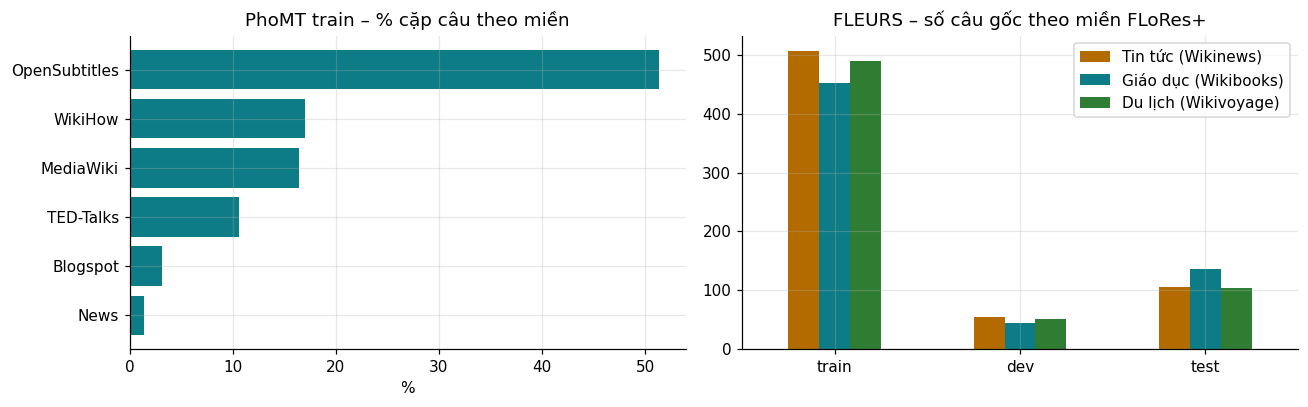

,Tin tức (Wikinews),Giáo dục (Wikibooks),Du lịch (Wikivoyage),tong
train,507,452,490,1449
dev,54,44,51,149
test,106,137,104,347


PhoMT chủ yếu là phụ đề phim (OpenSubtitles) – khác xa câu Wikipedia/Wikibooks của FLEURS → lý do dạy LoRA trên lời ASR của FLEURS.


In [9]:
pm = doc(R / "data/eda/eda_bang_mien_phomt.csv")
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
d = pm[pm.split == "train"].sort_values("pct"); ax[0].barh(d.mien, d.pct, color=XANH); ax[0].set_title("PhoMT train – % cặp câu theo miền"); ax[0].set_xlabel("%")
mt = J(R / "domain/mien_tom_tat.json")["so_cau_theo_mien"]
ten = {"wikibooks": "Giáo dục (Wikibooks)", "wikinews": "Tin tức (Wikinews)", "wikivoyage": "Du lịch (Wikivoyage)"}
df = pd.DataFrame(mt).T.rename(columns=ten); df.plot.bar(ax=ax[1], color=[CAM, XANH, LUC]); ax[1].set_title("FLEURS – số câu gốc theo miền FLoRes+")
ax[1].set_xlabel(""); ax[1].tick_params(axis="x", rotation=0); plt.tight_layout(); plt.show()
display(df.assign(tong=df.sum(axis=1)))
print("PhoMT chủ yếu là phụ đề phim (OpenSubtitles) – khác xa câu Wikipedia/Wikibooks của FLEURS → lý do dạy LoRA trên lời ASR của FLEURS.")

## 9. Xử lý mất cân bằng

{
 "tham_so": {
  "alpha": 0.5,
  "bins": [
   15,
   25,
   35,
   45
  ],
  "ti_le_phomt": 1.0,
  "seed": 42,
  "phomt_mien": null,
  "nhiet_do": 5.0,
  "muc_tieu": "max"
 },
 "v2": {
  "phomt_train_sach": 2977170,
  "fleurs_train_v1": 4468,
  "phomt_lay": 4468,
  "truoc_pct_fleurs": 0.15,
  "sau_pct_fleurs": 50.0,
  "mien_ghi_chu": "Không có nhãn miền từng dòng -> lấy ngẫu nhiên đều, tỉ lệ miền giữ như PhoMT gốc (OpenSubtitles ~51,4% theo paper). Có nhãn thì thêm --phomt_mien để cân bằng theo miền."
 },
 "meta": {
  "script": "viec4_can_bang_du_lieu.py",
  "time_utc": "2026-10-29T19:28:42+00:00",
  "versions": {
   "python": "3.11.1",
   "huggingface_hub": "0.24.6",
   "requests": "2.34.2"
  },
  "platform": "Windows-10-10.0.26200-SP0"
 }
}


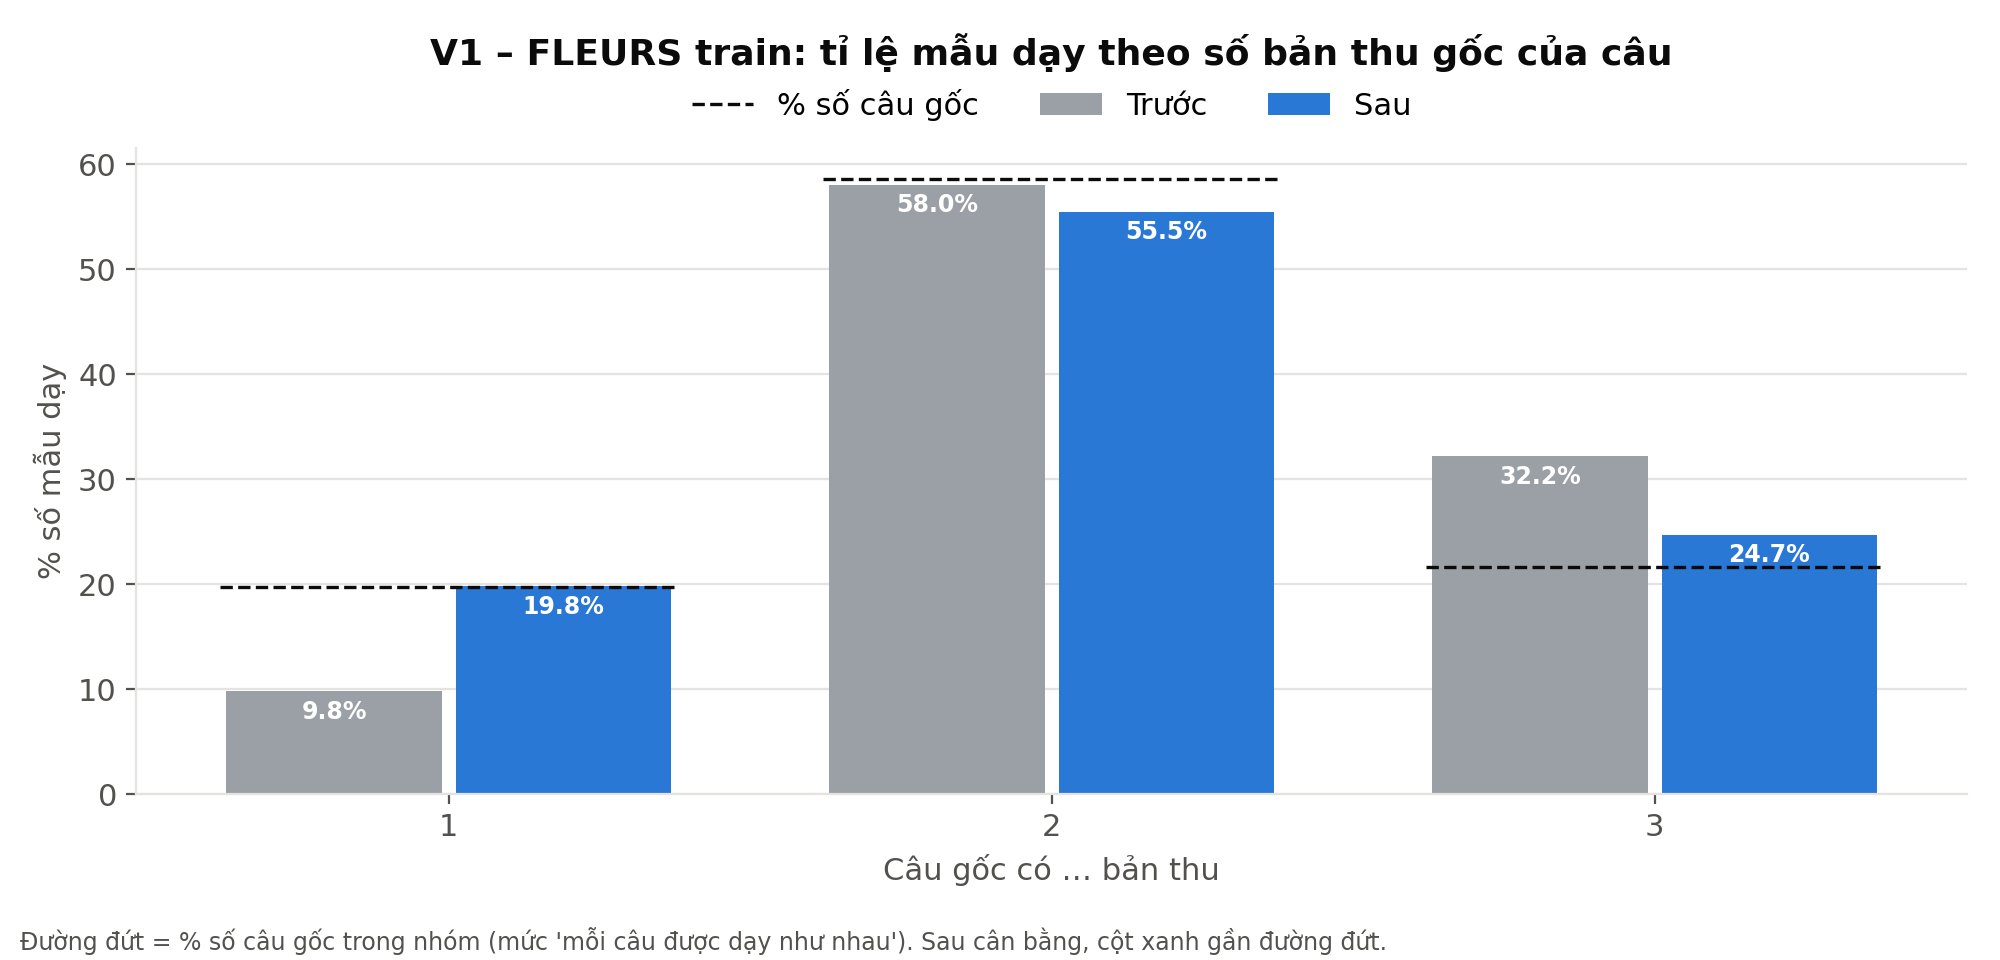

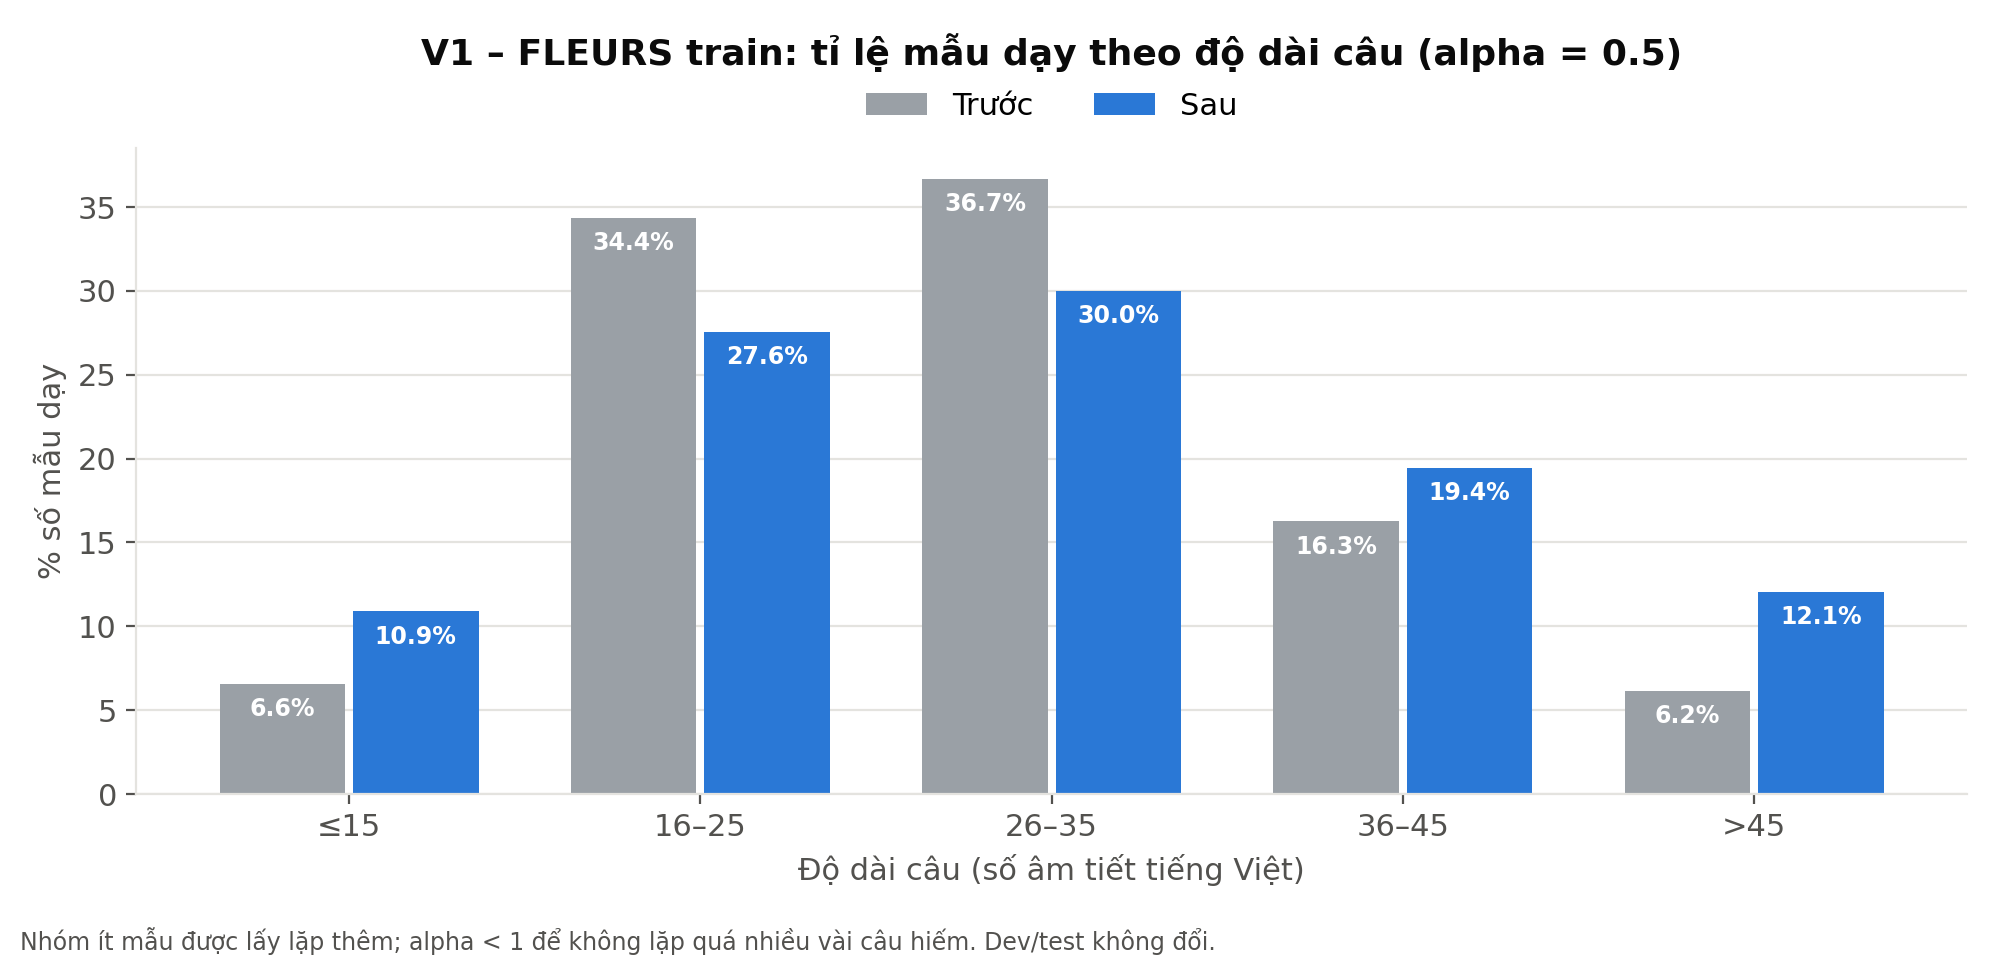

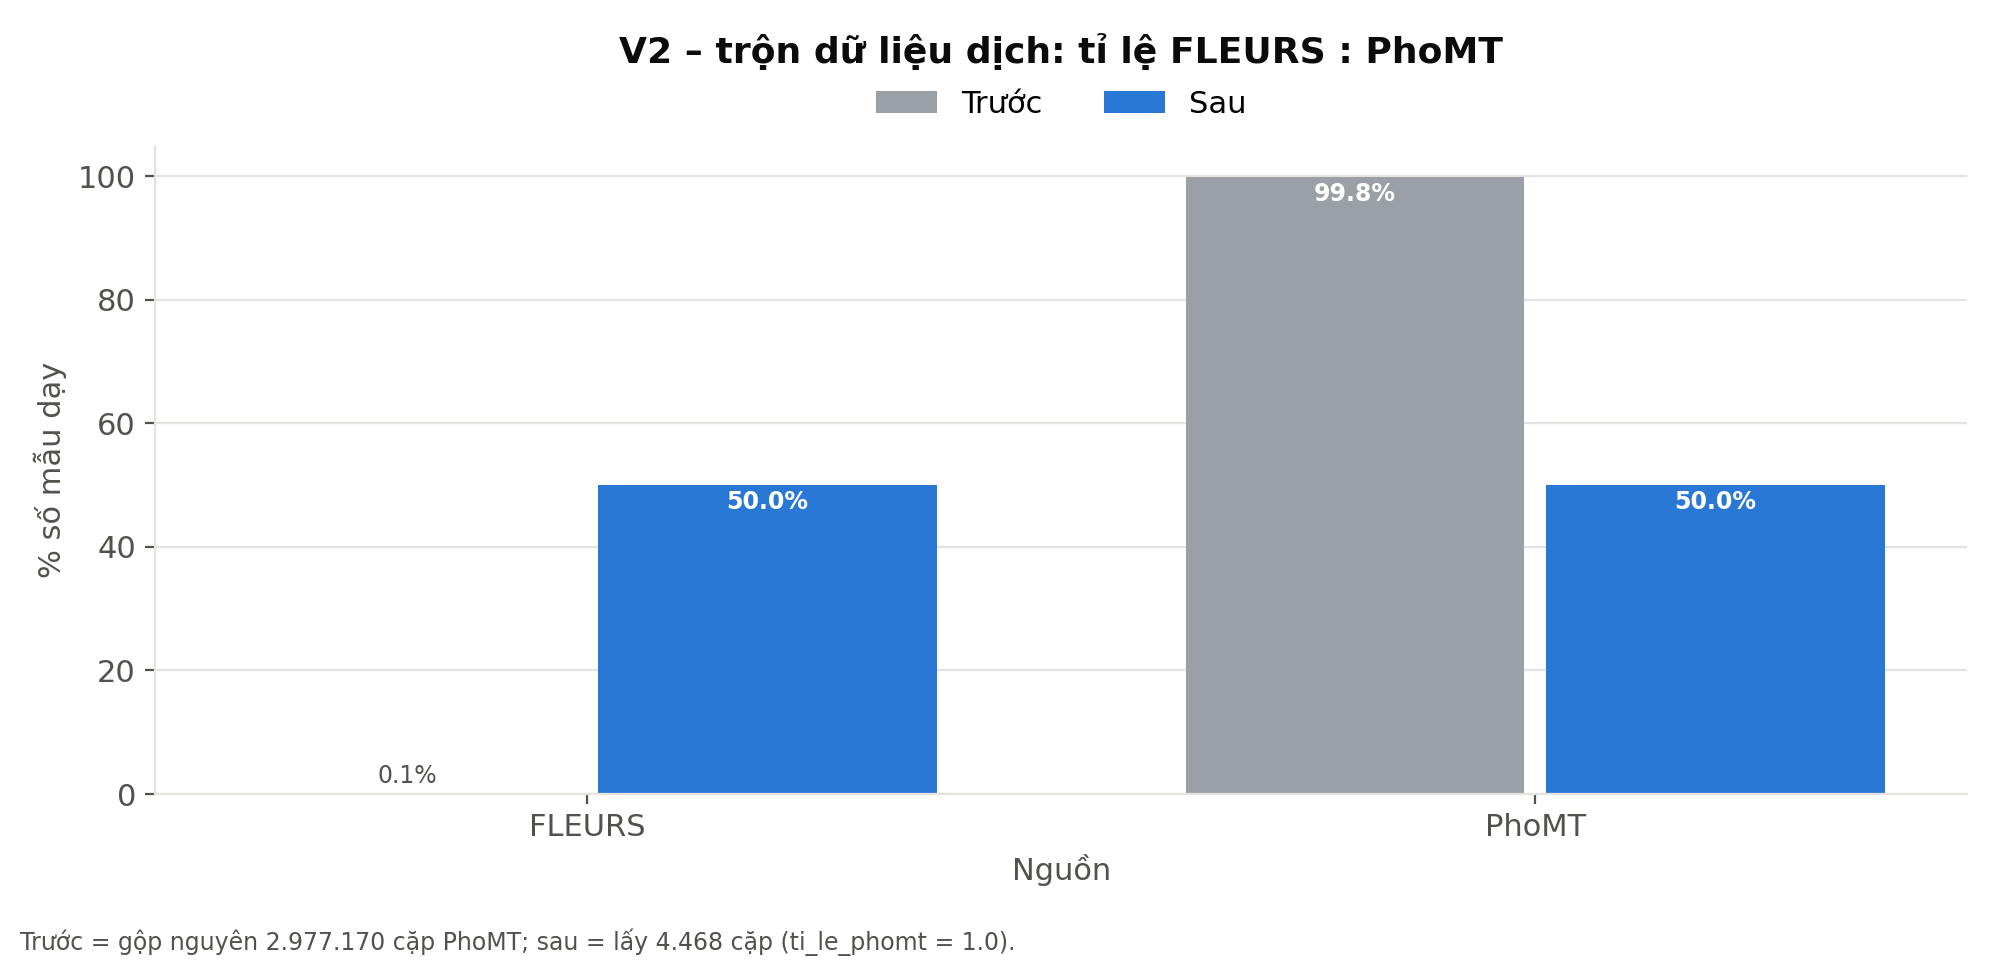

In [10]:
cb = J(R / "data/can_bang/can_bang_tom_tat.json")
print(json.dumps({k: v for k, v in cb.items() if not isinstance(v, (list, dict)) or len(str(v)) < 400}, ensure_ascii=False, indent=1)[:2500])
for f in ("can_bang_01_theo_cau.png", "can_bang_02_do_dai.png", "can_bang_03_nguon_v2.png"):
    p = R / "data/can_bang" / f
    if p.exists(): display(Image(filename=str(p), width=780))

## 10. Nhận xét EDA (định lượng)

In [11]:
display(Markdown((R / "data/eda/eda_nhan_xet.md").read_text(encoding="utf-8")))

# Nhận xét định lượng (tự sinh từ số đếm, mục 1.3 / slide 6)

- **Tỉ lệ tập VIVOS** (theo số mẫu): Train 93.88% (11.656 mẫu), Test 6.12% (760 mẫu). Giữ split gốc, không chia lại 80/10/10.
- **Tỉ lệ tập FLEURS** (theo số mẫu): Train 70.61% (2.926 mẫu), Val (dev) 8.71% (361 mẫu), Test 20.68% (857 mẫu). Giữ split gốc, không chia lại 80/10/10.
- **Tỉ lệ tập PHOMT** (theo số mẫu): Train 98.74% (2.977.170 mẫu), Val (dev) 0.62% (18.719 mẫu), Test 0.64% (19.151 mẫu). Giữ split gốc, không chia lại 80/10/10.
- **VIVOS Train**: 46 người nói, mỗi người 100–300 câu (TB 253.39); người nhiều nhất gấp 3.0 lần người ít nhất; 5 người nhiều nhất chiếm 12.87% số câu.
- **VIVOS Test**: 19 người nói, mỗi người 40–40 câu (TB 40); người nhiều nhất gấp 1.0 lần người ít nhất; 5 người nhiều nhất chiếm 26.32% số câu.
- **Giới tính FLEURS Train** (theo mẫu): Nam 25.7%, Nữ 74.3%.
- **Giới tính FLEURS Val (dev)** (theo mẫu): Nam 100.0%, Nữ 0.0%.
- **Giới tính FLEURS Test** (theo mẫu): Nam 100.0%, Nữ 0.0%.
- **Giới tính VIVOS Train** (theo mẫu): Nam 42.89%, Nữ 57.11%.
- **Giới tính VIVOS Train** (theo người nói): Nam 47.83%, Nữ 52.17%.
- **Giới tính VIVOS Test** (theo mẫu): Nam 63.16%, Nữ 36.84%.
- **Giới tính VIVOS Test** (theo người nói): Nam 63.16%, Nữ 36.84%.
- **Độ dài audio FLEURS Train**: TB 10.9 s, trung vị 10.38 s, 5%–95% trong khoảng 5.88–17.62 s; 4 bản thu (0.14%) dài hơn 30 s.
- **Độ dài audio FLEURS Val (dev)**: TB 11.91 s, trung vị 11.16 s, 5%–95% trong khoảng 6.0–21.32 s; 2 bản thu (0.55%) dài hơn 30 s.
- **Độ dài audio FLEURS Test**: TB 12.62 s, trung vị 11.64 s, 5%–95% trong khoảng 6.96–21.38 s; 7 bản thu (0.82%) dài hơn 30 s.
- **Độ dài audio VIVOS Train**: TB 4.61 s, trung vị 3.88 s, 5%–95% trong khoảng 2.06–9.34 s; 0 bản thu (0.0%) dài hơn 30 s.
- **Độ dài audio VIVOS Test**: TB 3.53 s, trung vị 3.47 s, 5%–95% trong khoảng 2.0–5.25 s; 0 bản thu (0.0%) dài hơn 30 s.
- Bản thu FLEURS test dài gấp 3.6 lần VIVOS test (TB 12.62 s so với 3.53 s) → kết quả trên VIVOS không đại diện audio dài.
- **FLEURS Train**: 1449 câu gốc, TB 2.02 bản thu/câu; phân bố 1 bản thu: 19.74%, 2 bản thu: 58.59%, 3 bản thu: 21.67%.
- **FLEURS Val (dev)**: 149 câu gốc, TB 2.42 bản thu/câu; phân bố 1 bản thu: 8.72%, 2 bản thu: 40.27%, 3 bản thu: 51.01%.
- **FLEURS Test**: 347 câu gốc, TB 2.47 bản thu/câu; phân bố 1 bản thu: 9.8%, 2 bản thu: 33.43%, 3 bản thu: 56.77%.
- **Miền PhoMT train** (theo paper): OpenSubtitles 51.37%, nhỏ nhất News 1.38% (chênh 37.3 lần); ở test, OpenSubtitles chiếm 49.94%. → Mô hình dịch nghiêng về văn nói kiểu phụ đề; FLEURS là câu kiểu Wikipedia (khác miền).
- **Độ dài câu**: FLEURS test TB 30.36 âm tiết/câu, VIVOS test 10.16, PhoMT test 17.84.
